# Economic narratives and consumer sentiment

**Panagiotis Housos | ph2606 | AI Applications in Finance | Final Project**

Information cutoff: October 13, 2026. Human validation is not completed; independent AI reviews are explicitly separate. Acquisition and model scoring run separately. The cells below rerun analysis from local frozen inputs. Raw datasets are excluded from Git under the established submission policy.

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'src/economics.py').exists(), 'Execute from the project root.'
expected_inputs = {'data/processed/monthly_dataset.csv': '8cfeac44c5132ab25883598bf3d4a0ad84cd10f6b7f5af43b8d16e55127f9b6a', 'data/processed/media_monthly.csv': '9643fa2ad6052d7f66020737aa2d2fd65f22362d1969f1fec623549cb5fc91fa', 'outputs/tables/provider_bias.csv': '06e999b8b87368f37891f4a25c347bf63ccd3e00278a513dfcc68cb3d3efeeb9', 'data/processed/investment_prices.csv': '2c86cd2c3bcd7441b5ccf29247a90c8832d30aff8477fd622001441cfddf1401'}
for name, expected in expected_inputs.items():
    path = ROOT / name
    assert path.exists(), f'Acquire required input: {name}'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, f'Input changed: {name}. Rerun analysis and rebuild deliverables before executing this notebook.'
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.precision', 4)

## Recompute the frozen empirical analysis

The economic feature matrix uses historical ALFRED snapshots. Media reconstruction is retrospective and subject to source selection and original-wording limitations. The package never invents missing records, exposure or human labels.

In [2]:
import subprocess, sys
for command in [['scripts/03_analyze.py'], ['-m', 'src.dynamics'], ['-m', 'src.investing', 'analyze']]:
    result = subprocess.run([sys.executable, *command], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout)
    assert result.returncode == 0, result.stderr
print('Primary analysis and exploratory dynamics recalculated from acquired observations.')

{
  "cutoff": "2026-10-13",
  "macro_timing": "Actual ALFRED historical vintages on the first calendar day of every forecast month; within-day release time not resolved, interpret origin as end of that day.",
  "target_limitation": "Official Michigan final historical tables, not historical target vintages; partial target revision leakage cannot be excluded.",
  "gdp_treatment": "No interpolation: predictor is growth of last quarterly real GDP observation present in each vintage.",
  "interval_caution": "Approximate HAC parameter + residual intervals; empirical past-OOS-error intervals after 24 calibration observations. Report realized coverage; no guarantee under structural breaks.",
  "latest_final_forecast": {
    "month": "2026-09-01",
    "prediction_date": "2026-09-01",
    "target": "sentiment",
    "model": "M1_economic",
    "observed": 48.1,
    "prediction": 70.66545331146001,
    "gap": -22.56545331146001,
    "error": -22.56545331146001,
    "lower_95": 50.2316036338248,
  

{
  "pool_n": 80,
  "holdout_n": 44,
  "metrics": [
    {
      "model": "D_macro",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.3005264839,
      "mae": 3.498214615,
      "mean_error": 0.2859605397,
      "analysis_status": "exploratory",
      "rmse_gain_percent_vs_baseline": null,
      "comparison_baseline": null
    },
    {
      "model": "D_macro_AR",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.2226540069,
      "mae": 3.4241520681,
      "mean_error": 0.236443637,
      "analysis_status": "exploratory",
      "rmse_gain_percent_vs_baseline": null,
      "comparison_baseline": null
    },
    {
      "model": "D_macro_AR_media",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.2234114057,
      "mae": 3.3866487028,
      "mean_error": 0.2249447442,
      "analysis_status": "explor

                   label  net_total_return  net_cagr  max_drawdown  average_equity_weight
Macro + trend allocation          0.880100  0.055209     -0.201055               0.634109
        SPY buy-and-hold          3.537800  0.137393     -0.337173               1.000000
       Treasury-bill ETF          0.252940  0.019379     -0.002309               0.000000
             Fixed 60/40          1.801621  0.091650     -0.207803               0.600947
{
  "hac_tests": {
    "primary_minus_static": {
      "annualized_daily_intercept": -0.03480351865098805,
      "lower_95": -0.06372102984216918,
      "upper_95": -0.005886007459806919,
      "pvalue": 0.01832897913462651,
      "n": 2955,
      "market_beta": null,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    },
    "bil_relative_market_model": {
      "annualized_daily_intercept": -0.017837458040149648,
      "lower_95": -0.048388109862808365,
      "upper_95": 0.012713193782509074,
      "pvalue": 0.252476657251

## Persistence and differenced-model sensitivity

These checks were added after the primary analysis and are exploratory. ADF and KPSS have different null hypotheses; structural breaks limit either interpretation. The differenced models use the same 44 test months and a separately identified two-contrast loss-test family.

In [3]:
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_unit_root.csv'))
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_differenced_metrics.csv'))
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_loss_hac.csv'))

,sample,variable,n,start,end,lag1_correlation,adf_statistic,...,kpss_statistic,kpss_pvalue_tabulated,kpss_pvalue_boundary,kpss_lags_auto,adf_null,kpss_null,interpretation
0,historical,sentiment,201,2010-01-01,2026-09-01,0.9592,-0.4018,...,0.7236,0.0114,within tabulated range,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
1,historical,unemployment,201,2010-01-01,2026-09-01,0.9363,-2.8838,...,1.2641,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
2,historical,pce_yoy,201,2010-01-01,2026-09-01,0.9824,-1.9677,...,0.7878,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
3,historical,gdp_qoq_annualized,201,2010-01-01,2026-09-01,0.5635,-4.3157,...,0.0246,0.1000,p > 0.10,1,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
4,historical,price_36m,201,2010-01-01,2026-09-01,0.9956,-1.4358,...,1.1486,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
5,historical,real_income_yoy,201,2010-01-01,2026-09-01,0.3700,-4.5556,...,0.0879,0.1000,p > 0.10,8,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
6,historical,media_tone_lag1,80,2020-02-01,2026-09-01,0.2231,-7.0025,...,0.1979,0.1000,p > 0.10,3,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
7,historical,delta_sentiment,200,2010-02-01,2026-09-01,0.0727,-8.8224,...,0.2467,0.1000,p > 0.10,10,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
8,common_media_pool,sentiment,80,2020-02-01,2026-09-01,0.8960,-0.7997,...,0.8270,0.0100,p < 0.01,5,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
9,common_media_pool,unemployment,80,2020-02-01,2026-09-01,0.8189,-2.2066,...,0.5596,0.0282,within tabulated range,5,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...


,model,n,start,end,rmse,mae,mean_error,analysis_status,rmse_gain_percent_vs_baseline,comparison_baseline
0,D_macro,44,2023-02-01,2026-09-01,4.3005,3.4982,0.2860,exploratory,NaN,NaN
1,D_macro_AR,44,2023-02-01,2026-09-01,4.2227,3.4242,0.2364,exploratory,NaN,NaN
2,D_macro_AR_media,44,2023-02-01,2026-09-01,4.2234,3.3866,0.2249,exploratory,-0.0179,D_macro_AR
3,D_macro_media,44,2023-02-01,2026-09-01,4.2729,3.4134,0.2692,exploratory,0.6418,D_macro


,family,augmented,baseline,n,start,end,hac_maxlags,primary_bandwidth,mean_squared_loss_difference,hac_se_mean_loss_difference,hac_pvalue_two_sided,family_size,interpretation,bh_qvalue_within_bandwidth_family
0,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,3,True,-0.2245,3.5024,0.9489,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
1,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,3,True,-1.3620,5.3445,0.7988,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
2,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,3,True,-0.4142,0.9502,0.6629,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
3,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,6,False,-0.2245,3.0742,0.9418,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
4,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,6,False,-1.3620,4.8012,0.7767,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
5,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,6,False,-0.4142,1.0104,0.6818,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
6,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,12,False,-0.2245,2.7289,0.9344,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
7,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,12,False,-1.3620,3.5679,0.7027,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
8,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,12,False,-0.4142,1.0795,0.7012,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
9,exploratory_differenced_two_contrasts,D_macro_media,D_macro,44,2023-02-01,2026-09-01,3,True,-0.2366,0.7519,0.7530,2,Exploratory nested-model loss comparison; limited sample; not causal,0.9910


## Independent AI diagnostic: class and source concordance

These are AI development references, not human ground truth. The original pool has 300 items; final-corpus eligibility and mixed/uncertain exclusions are explicit. Small source/class cells have unstable estimates. Required human validation remains pending.

In [4]:
path = ROOT / 'outputs/ai_diagnostic_validation_metrics.json'
ai = json.loads(path.read_text()) if path.exists() else {}
if ai:
    display(pd.Series({k: ai.get(k) for k in ['label_type','completed_independent_pairs','tone_agreement','tone_cohens_kappa','annotation_pool_final_eligible_n','annotation_pool_final_excluded_n','human_specific_requirement_satisfied']}))
    rows, classes = [], []
    for annotator, models in ai['model_reference_concordance'].items():
        for model, entry in models.items():
            for source, result in entry['by_source'].items():
                rows.append({'reference': annotator, 'model': model, 'source': source, 'n': result['n'], 'agreement': result['agreement'], 'macro_F1_concordance': result['macro_f1_reference_concordance']})
            for label, result in entry['class_concordance'].items():
                classes.append({'reference': annotator, 'model': model, 'class': label, **result})
    display(pd.DataFrame(rows))
    display(pd.DataFrame(classes))
else:
    print('Independent AI diagnostic inputs are unavailable in this clone; no human labels are inferred.')

label_type                              ai_diagnostic
completed_independent_pairs                       300
tone_agreement                                   0.92
tone_cohens_kappa                              0.8895
annotation_pool_final_eligible_n                  277
annotation_pool_final_excluded_n                   23
human_specific_requirement_satisfied            False
dtype: object

,reference,model,source,n,agreement,macro_F1_concordance
0,annotator_a,contextual,Associated Press,35,0.7143,0.6919
1,annotator_a,contextual,Colorado Sun,37,0.8108,0.7821
2,annotator_a,contextual,Gothamist,31,0.7742,0.7643
3,annotator_a,contextual,Hacker News,36,0.7500,0.7355
4,annotator_a,contextual,NPR,36,0.7500,0.7394
5,annotator_a,contextual,Reuters,36,0.6667,0.6257
6,annotator_a,contextual,Texas Tribune,31,0.6452,0.5556
7,annotator_a,dictionary,Associated Press,35,0.6857,0.6646
8,annotator_a,dictionary,Colorado Sun,37,0.5946,0.5722
9,annotator_a,dictionary,Gothamist,31,0.4839,0.4593


,reference,model,class,precision,recall,f1,support
0,annotator_a,contextual,negative,0.9362,0.7273,0.8186,121
1,annotator_a,contextual,neutral,0.4024,0.8049,0.5366,41
2,annotator_a,contextual,positive,0.8485,0.7000,0.7671,80
3,annotator_a,dictionary,negative,0.8602,0.6612,0.7477,121
4,annotator_a,dictionary,neutral,0.3077,0.5854,0.4034,41
5,annotator_a,dictionary,positive,0.6901,0.6125,0.6490,80
6,annotator_b,contextual,negative,0.9570,0.7120,0.8165,125
7,annotator_b,contextual,neutral,0.3780,0.7561,0.5041,41
8,annotator_b,contextual,positive,0.7794,0.6883,0.7310,77
9,annotator_b,dictionary,negative,0.8913,0.6560,0.7558,125


## Political-name and source-label stress tests

The original text is held constant except for the specified change. Changed names can change meaning. Class switches do not prove political discrimination or factual bias.

In [5]:
media_summary = json.loads((ROOT / 'outputs/media_summary.json').read_text())
display(pd.DataFrame(media_summary['perturbation']['variant_comparisons']))
print('Source-prefix paired mean absolute tone difference:', media_summary['perturbation']['source_pair_mean_absolute_delta'])
print('Factual-calibration status:', media_summary.get('factual_calibration'))

,test,n,mean_absolute_tone_delta,class_switch_rate
0,political_name_swap,100,0.0760,0.05
1,source_prefix_Gothamist,100,0.1021,0.12
2,source_prefix_Reuters,100,0.0830,0.12


Source-prefix paired mean absolute tone difference: 0.05627288064146129
Factual-calibration status: {'numeric_eligible_titles': 313, 'purposive_same_release_day_values_checked': 8, 'numerically_aligned': 8, 'population_factual_error_rate': None, 'fully_verified_definition_period_and_intraday_vintage_claims': 0, 'interpretation': 'Eight purposive unemployment-title percentages match archived official release values; this is numeric alignment, not an estimate of overall factual accuracy. Most titles omit precise definition or period; RSS intraday timestamps are unreliable. No factual-error rate is estimated.', 'checks_path': 'data/processed/factual_calibration_checks.csv', 'benchmarks_path': 'data/raw/media/official_claim_benchmarks.json'}


## News-provider comparison: matched official releases

A separate supplemental sample includes CNBC and Fox brands. The provider bars use a common set of releases and a defined peer reference. This is a relative negative-framing proxy, not a factual or ideological rating. The original forecast corpus and 300-title AI review remain separate; the new providers do not have independent human validation.

In [6]:
provider_table = pd.read_csv(ROOT / 'outputs/tables/provider_bias.csv')
display(provider_table)
provider_summary = json.loads((ROOT / 'outputs/tables/provider_bias_summary.json').read_text())
display(pd.Series(provider_summary, name='provider_comparison_protocol'))

,provider,bias_pp,lower_95,upper_95,raw_percentile_lower_95,raw_percentile_upper_95,n_titles,...,one_hash_title_bias_pp,event_bootstrap_lower_95,event_bootstrap_upper_95,coverage,same_common_events,comparison_status,ci_contains_zero
0,Associated Press,NaN,NaN,NaN,NaN,NaN,14,...,NaN,NaN,NaN,0.7222,False,outside_main_common_support_no_comparable_bar,NaN
1,Bloomberg,20.8333,-1.6667,55.0000,-1.6667,55.0000,15,...,2.0000e+01,-1.6667,55.0000,0.3333,True,main_common_event_panel,True
2,CNBC,-9.1667,-19.1667,-0.8333,-19.1667,-0.8333,15,...,-5.9212e-16,-19.1667,-0.8333,0.3333,True,main_common_event_panel,False
3,CNN,0.8333,-10.0000,14.1667,-10.0000,14.1667,9,...,-5.9212e-16,-10.0000,14.1667,0.3333,True,main_common_event_panel,True
4,Fox Business,5.8333,-6.6667,19.1667,-6.6667,19.1667,15,...,-5.9212e-16,-6.6667,19.1667,0.3333,True,main_common_event_panel,True
5,Fox News,-12.5000,-28.3333,-0.8333,-28.3333,-0.8333,8,...,-2.0000e+01,-28.3333,-0.8333,0.3333,True,main_common_event_panel,False
6,NPR,NaN,NaN,NaN,NaN,NaN,19,...,NaN,NaN,NaN,0.7222,False,outside_main_common_support_no_comparable_bar,NaN
7,Reuters,NaN,NaN,NaN,NaN,NaN,23,...,NaN,NaN,NaN,0.8889,False,outside_main_common_support_no_comparable_bar,NaN
8,Wall Street Journal,-5.8333,-12.5000,-0.8333,-12.5000,-0.8333,10,...,-5.9212e-16,-12.5000,-0.8333,0.3333,True,main_common_event_panel,False


status                                                                                                    complete
metric_name                                               same-event relative negative framing (percentage points)
formula                                      100 * mean_e[negative-title share(provider,e) - mean_other_provide...
interpretation                               Higher means more sampled titles classified negative than same-eve...
interval_interpretation                      Conditional95% month-resampling stability ranges for this fixed sa...
affiliation_note                             Fox News and Fox Business are separate queried brands with shared ...
not_measured                                 [factual inaccuracy, partisan or ideological bias, intent, audienc...
mode                                                                          identical_common_events_equal_weight
main_providers                                 [CNBC, Fox News, Fox Business, CN

## Retrospective investment extension (October 17)

The primary macro/trend rule was fixed before performance calculation; the simpler monthly 60% SPY / 40% BIL benchmark is preferred after the comparison. Neither is an untouched holdout. Costs include entry, exit and both traded legs. Gap and media overlays use retrospective inputs. All 44 gaps are negative; this is exposure, not demonstrated timing.

In [7]:
investment = json.loads((ROOT / 'outputs/tables/investment_summary.json').read_text())
performance = pd.read_csv(ROOT / 'outputs/tables/investment_metrics.csv')
display(performance.loc[performance.cost_bps.eq(10)])
print('Full-period cost sensitivity:')
display(performance.loc[performance['sample'].eq('full'), ['model','cost_bps','net_cagr','max_drawdown','annual_gross_turnover']])
print('Primary HAC diagnostics:')
display(pd.DataFrame(investment['hac_tests']).T)
print('Original two-test overlay family (unadjusted for exposure):')
display(pd.DataFrame(investment['overlay_tests']))
print('Post-result exposure diagnosis:')
print(json.dumps(investment['exposure_diagnostics'], indent=2))
print(investment['practical_conclusion'])

,sample,model,label,cost_bps,allocation_periods,start,end,...,net_cagr,volatility,max_drawdown,average_equity_weight,annual_gross_turnover,bil_relative_sharpe,terminal_value_10000
4,full,Macro_trend_80_20,Macro + trend allocation,10,141,2015-01-02,2026-10-02,...,0.0552,0.0955,-0.2011,0.6341,3.0866,0.4085,18801.0005
5,full,SPY_hold,SPY buy-and-hold,10,141,2015-01-02,2026-10-02,...,0.1374,0.1753,-0.3372,1.0000,0.1702,0.7131,45377.9997
6,full,BIL_hold,Treasury-bill ETF,10,141,2015-01-02,2026-10-02,...,0.0194,0.0027,-0.0023,0.0000,0.1702,-0.4131,12529.3950
7,full,Static_60_40,Fixed 60/40,10,141,2015-01-02,2026-10-02,...,0.0917,0.1034,-0.2078,0.6009,0.3705,0.7138,28016.2076
18,common_44,Macro_trend_80_20,Macro + trend allocation,10,44,2023-02-02,2026-10-02,...,0.1231,0.0949,-0.0836,0.6924,3.8789,0.8043,15299.5329
19,common_44,SPY_hold,SPY buy-and-hold,10,44,2023-02-02,2026-10-02,...,0.1970,0.1486,-0.1876,1.0000,0.5457,0.9872,19321.8116
20,common_44,BIL_hold,Treasury-bill ETF,10,44,2023-02-02,2026-10-02,...,0.0449,0.0025,-0.0010,0.0000,0.5457,-0.7406,11746.8588
21,common_44,Static_60_40,Fixed 60/40,10,44,2023-02-02,2026-10-02,...,0.1353,0.0882,-0.1133,0.6011,0.7045,0.9805,15918.5193
22,common_44,Gap_overlay,Exploratory gap tilt,10,44,2023-02-02,2026-10-02,...,0.1382,0.1082,-0.1026,0.7923,3.8448,0.8415,16067.6806
23,common_44,Media_overlay,Exploratory media tilt,10,44,2023-02-02,2026-10-02,...,0.1080,0.0825,-0.0712,0.5949,4.0147,0.7470,14560.2066


Full-period cost sensitivity:


,model,cost_bps,net_cagr,max_drawdown,annual_gross_turnover
0,Macro_trend_80_20,0,0.0585,-0.1953,3.0883
1,SPY_hold,0,0.1376,-0.3372,0.1702
2,BIL_hold,0,0.0196,-0.0021,0.1702
3,Static_60_40,0,0.0921,-0.2078,0.3706
4,Macro_trend_80_20,10,0.0552,-0.2011,3.0866
5,SPY_hold,10,0.1374,-0.3372,0.1702
6,BIL_hold,10,0.0194,-0.0023,0.1702
7,Static_60_40,10,0.0917,-0.2078,0.3705
8,Macro_trend_80_20,25,0.0503,-0.2096,3.0839
9,SPY_hold,25,0.1371,-0.3372,0.1700


Primary HAC diagnostics:


,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method
primary_minus_static,-0.0348,-0.0637,-0.0059,0.0183,2955,None,OLS HAC(21); annualized arithmetic daily intercept
bil_relative_market_model,-0.0178,-0.0484,0.0127,0.2525,2955,0.4542,OLS HAC(21); annualized arithmetic daily intercept


Original two-test overlay family (unadjusted for exposure):


,model,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method,bh_qvalue
0,Gap_overlay,0.0148,0.0020,0.0275,0.0233,920,None,OLS HAC(21); annualized arithmetic daily intercept,0.0233
1,Media_overlay,-0.0147,-0.0272,-0.0021,0.0223,920,None,OLS HAC(21); annualized arithmetic daily intercept,0.0233


Post-result exposure diagnosis:
{
  "status": "post-result explanatory diagnostics; conditional HAC inference, not an additional confirmatory family",
  "gap_negative_origins": 44,
  "media_negative_origins": 43,
  "origins": 44,
  "beta_adjusted_overlay_differences": [
    {
      "model": "Gap_overlay",
      "annualized_daily_intercept": 0.0001776593035039356,
      "lower_95": -2.899781088285041e-05,
      "upper_95": 0.0003843164178907216,
      "pvalue": 0.0919992162763555,
      "n": 920,
      "market_beta": 0.09910694116864897,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    },
    {
      "model": "Media_overlay",
      "annualized_daily_intercept": -0.0005203498320996874,
      "lower_95": -0.002305944622293636,
      "upper_95": 0.0012652449580942615,
      "pvalue": 0.5678886808357619,
      "n": 920,
      "market_beta": -0.09601121303001092,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    }
  ],
  "interpretation": "All n

## Question, evidence and practical result

This project asks whether economic narratives help explain the divergence between the University of Michigan Index of Consumer Sentiment and headline economic conditions before the November 3, 2026 midterm elections. It separates household pressures, selective information or framing, and measurement or model inadequacy. Negative coverage and pessimistic consumers are not presumed biased.

The first result is a measurement warning. The supplied workbook is not a release-vintage dataset, its latest PCE value does not match official headline inflation, and its Q3 GDP value precedes the official release. Official economic snapshots replace those values in the main analysis. For the latest completed-month economic forecast, observed sentiment is 48.1, the M1 prediction is 70.7, and the gap is -22.6 points. The mean 2026 assessment gap is -21.9 points. These residuals depend on the model.

On the common 44-month chronological assessment sample, adding the specified media variables reduces RMSE by 0.01 index points relative to M1. With lagged sentiment included, media reduces RMSE by 0.04 points. Predictive improvement, if present, cannot distinguish genuine household pressure from framing, reverse causality or omitted shocks. A separate same-release provider comparison, including CNBC and Fox brands, is shown on page 11.

In [8]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[0][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Evidence component,What is actually available
0,Economic baseline,Monthly data from 2010; historical ALFRED macro vintages; headline...
1,Content sample,"3,787 sampled titles across 82 calendar months; national, local an..."
2,Monitoring,October preliminary sentiment 46.3; incomplete October media; cuto...
3,Validation status,AI and dictionary diagnostics; two independent HUMAN annotators ar...
4,Identification,Observational analysis and a detailed prospective causal-design pr...


The separate October 17, 2026 investment extension favors a simple benchmark within this historical sample: monthly 60% SPY / 40% BIL earned 9.17% net CAGR, versus 5.52% for the fixed macro/trend rule, through October 2, 2026. Both were historically profitable after modeled costs; neither establishes alpha or prospective profitability. The investment conclusion and risk comparison are on page 12.

## 1. Input audit and source provenance

The two supplied files were read before analysis. The spreadsheet has four separate date/value pairs rather than one aligned panel: U-3 unemployment, Michigan headline sentiment, a column labeled PCE YoY, and quarterly GDP growth. Values must be joined by their own observation periods. Month-end labels describe the month; they do not establish the day information became available. The sheet provides no original source URLs, retrieval clocks, publication dates or revision vintages.

In [9]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[1][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Input issue,Official check and treatment
0,October sentiment 46.3,Michigan released a preliminary October estimate October 9; retain...
1,Q3 2026 GDP 3.7,Advance estimate scheduled October 29; quarantine throughout the O...
2,August PCE YoY 3.00759,All 584 workbook inflation values match core PCE within 0.0001 per...
3,Missing October 2025 U-3,BLS collected no October CPS data during the shutdown; do not inte...
4,Historical GDP revisions,Q2 2026 third estimate and annual updates cannot enter forecasts b...


Official sources are the BLS Current Population Survey, BEA national accounts and PCE releases, and Michigan Surveys of Consumers. ALFRED redistributes BLS/BEA series with historical vintages; it is the transport for the as-of feature matrix, not a different economic definition. Raw payload bytes, exact request URLs, retrieval times and SHA-256 hashes are retained locally. The workbook audit and source provenance are computed and retained as local tables.

Acquisition is distinct from interpretation. A current downloaded survey history is used as the final monthly outcome series, while the preliminary October release is kept as a separate monitoring observation. Historical survey-target revisions and original media wording cannot be fully reconstructed. The submitted notebook preserves aggregate exhibits; the repository excludes raw and derived datasets under the established course submission policy. Snapshot hashes support local verification, but code-only re-downloads cannot guarantee identical mutable-feed results.

## 2. Economic definitions and prediction timing

Each forecast uses the first calendar day of its target month as its historical ALFRED snapshot. Since within-day release time is unresolved, the origin is interpreted as the end of that day. The three required predictors are the latest published seasonally adjusted U-3 unemployment rate, headline PCE year-over-year inflation, and the latest published quarterly real GDP quarter-over-quarter annualized growth. Each row preserves observation periods; age fields count days since the reference period began, not days since publication. GDP is carried as a known quarterly predictor; it is never interpolated into synthetic monthly GDP observations.

In [10]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[2][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Measure,Transformation or interpretation
0,Headline PCE inflation,"100 × (PCEPI_t / PCEPI_(t−12) − 1), computed within the same vintage."
1,GDP QoQ annualized,100 × [(real GDP_q / real GDP_(q−1))^4 − 1].
2,GDP YoY sensitivity,100 × (real GDP_q / real GDP_(q−4) − 1); different from annualized...
3,Cumulative price control,"36-month PCE price increase, using the same origin’s price-index h..."
4,Household-income control,Real disposable personal income YoY; aggregate income is still not...


A historical vintage establishes that a value was available by the prediction origin; it does not recover the precise publication clock of every historical observation. Recent official release dates are recorded separately. Transformations require the exact calendar lag, so missing periods cannot be silently bridged. Later GDP revisions and chain-base changes are kept within their own vintages.

The survey covers personal finances, business conditions and buying conditions, including expectations. It is not a direct referendum on unemployment, inflation and GDP. Headline, Current Economic Conditions and Consumer Expectations are analyzed separately. The distinction matters because inflation can fall while prices remain well above the level households remember; real GDP can grow while housing costs, debt service or the distribution of income worsen for some households.

Training uses only targets before each origin. Lagged final sentiment provides a persistence benchmark. First-day predictions precede the published index, but some interviews began the previous month, so the origin need not precede every respondent’s interview. Partial October news cannot be backfilled into an October 1 prediction. Media lags are formed on the full monthly grid before removing incomplete rows.

## 3. Out-of-sample economic baseline and uncertainty

M1 estimates sentiment from unemployment, headline PCE inflation and quarterly annualized GDP growth, using at least 60 earlier months. Separate Current Conditions and Expectations models have historical test RMSEs of 16.50 and 10.44 points. A negative headline gap is observed sentiment minus its chronological prediction. It measures unexplained pessimism under M1, with uncertainty from model specification and structural instability; it is not an estimate of perceptual bias.

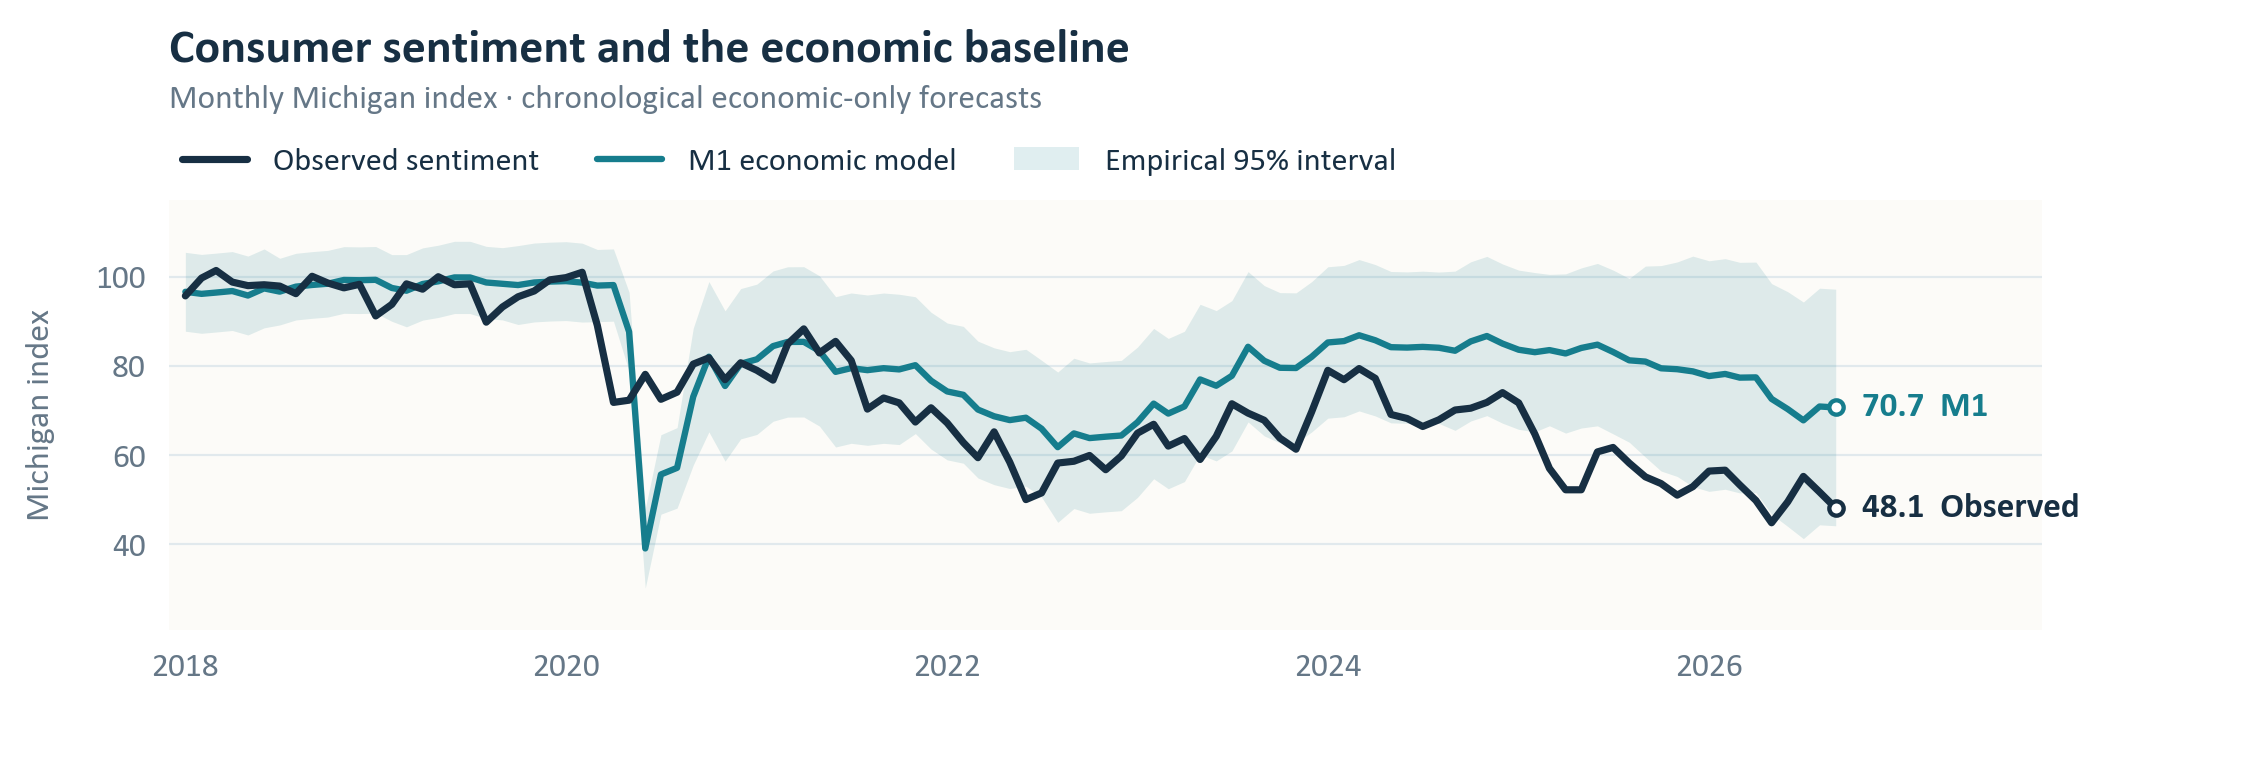

In [11]:
display(Image(filename=str(ROOT / 'outputs' / 'economic_forecast.png')))

Observed final headline sentiment and chronological M1 forecasts. Empirical intervals use only earlier forecast errors; absence of an early band means insufficient calibration history.

Over the 141 common historical test months, M1 RMSE is 12.35 index points versus 4.26 for last-observation persistence. M1 approximate interval coverage is 72.3%; its empirical interval covers 78.4% of 116 calibrated observations. Strong residual autocorrelation and undercoverage show that the simple macro baseline is inadequate. September sentiment 48.1 falls below its approximate interval [50.23, 91.10] but inside its past-error interval [44.13, 97.21]. The claimed discrepancy depends on how uncertainty is modeled.

Residual persistence, pandemic disruption and the post-2021 inflation experience challenge a stable linear mapping from three aggregates to sentiment. Rolling-window, seasonality, GDP-growth-definition and survey-method sensitivities are included in the analytical tables. An AR1 benchmark and macro models with lagged sentiment test whether any apparent improvement merely reflects persistence. Coefficient paths and HAC uncertainty are supplied as diagnostics rather than one invariant structural relationship.

## 4. Household pressures and survey comparability

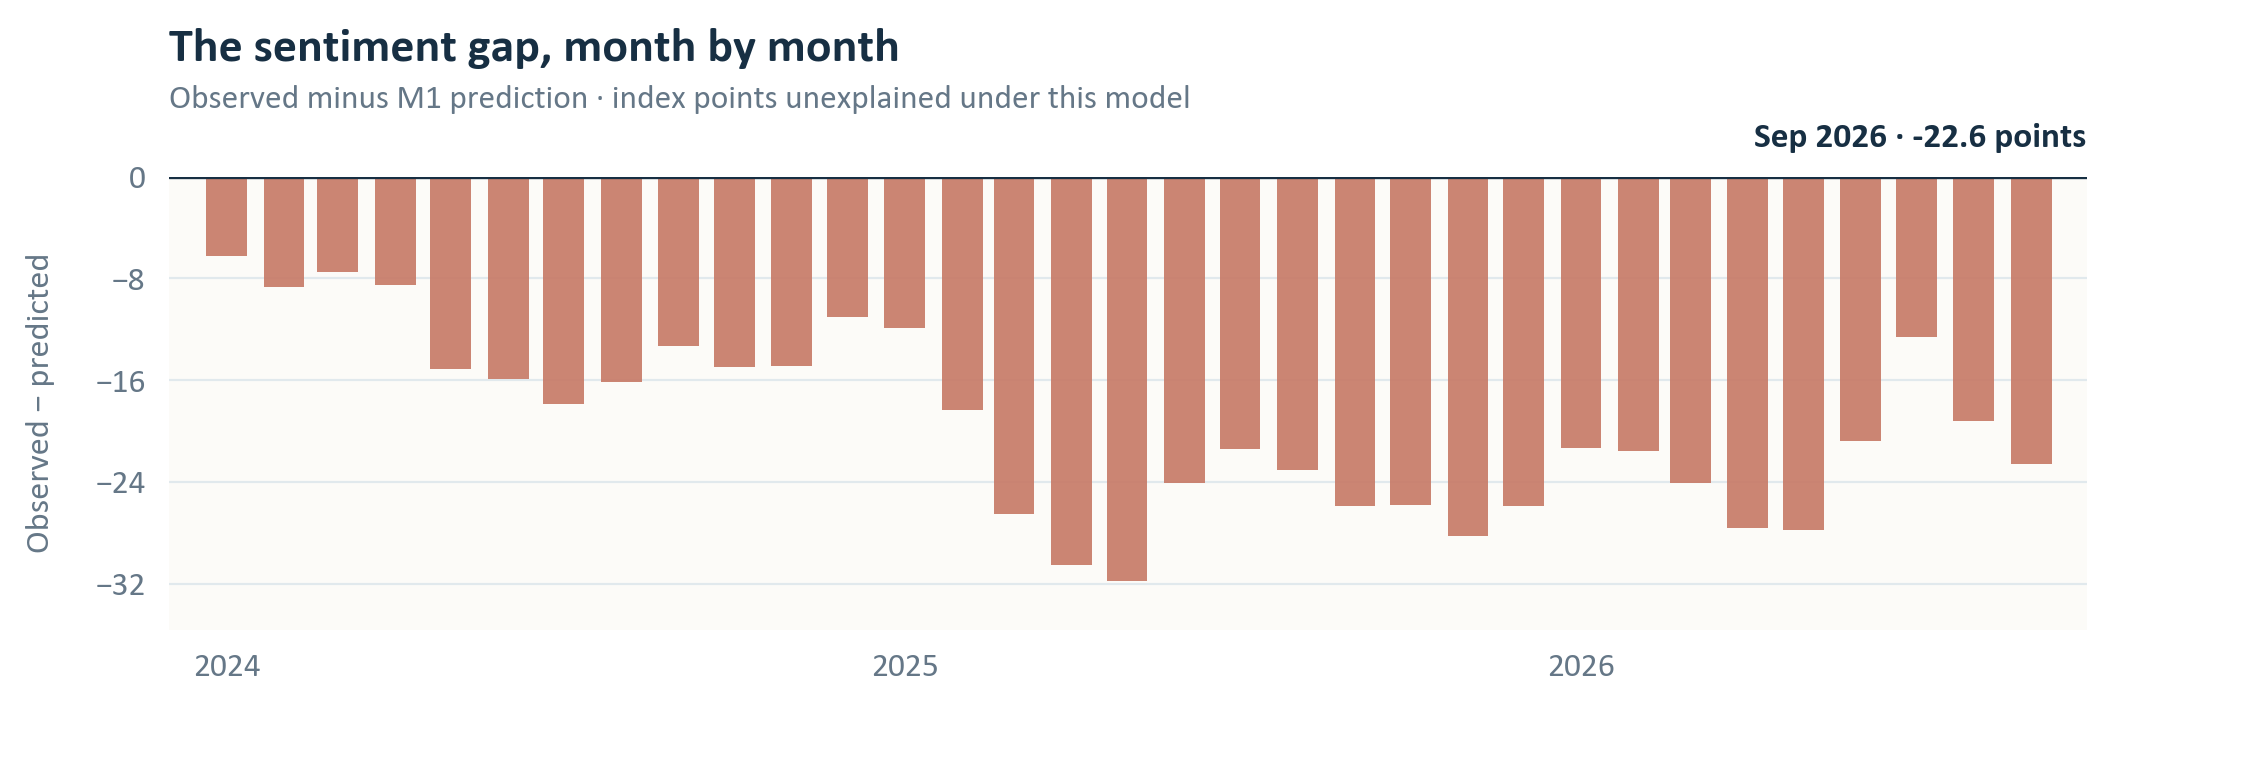

In [12]:
display(Image(filename=str(ROOT / 'outputs' / 'recent_gap.png')))

Recent observed-minus-M1 residuals. These are model errors, not percentages of irrational consumers or attributable media effects.

The first alternative explanation is omitted economic pressure. Real disposable income growth and the cumulative 36-month PCE price increase add distinct information: current inflation measures the rate of change, while the accumulated increase measures the elevated price level. The controls are manageable and reproducible, but they do not exhaust housing affordability, consumer credit, inequality, regional shocks or job insecurity. A remaining residual can still reflect those omissions.

Adding household controls lowers historical RMSE from 12.35 to 11.01 across 141 months. On the 44-month media-overlap sample, controls yield 12.01 versus 11.85 for M1. Their predictive benefit is period-dependent, not evidence that one omitted pressure explains the gap.

The second alternative is survey measurement. Michigan’s announced web shares were 25%, 50%, 75% and 100% from April through July 2024. A ramp sensitivity reduces September’s gap to −3.99 points, while the autoregressive macro model yields −4.64 instead of M1’s −22.57. The ramp confounds every coincident post-transition change and cannot identify a causal mode effect. Michigan’s July 2026 report, revised September 4, also finds the 2026 low persists under consistent-mode comparisons; the sensitivity cannot establish that the survey change caused pessimism.

Michigan documents partisan differences and releases demographic breakdowns. The October preliminary description emphasizes lower-income consumers and smaller stock portfolios; these published observations are contextual evidence, not respondent-level controls. No individual party identification, exposure, geography, recall or beliefs are observed in the monthly analytic panel. The project does not manufacture subgroup estimates or equate a national aggregate with any specific group.

Historical sentiment has lag-one correlation 0.959; ADF p=0.910 and KPSS p=0.011 warn against interpreting persistent levels mechanically. Breaks can mimic nonstationarity. In an exploratory differenced model with lagged sentiment change, adding media changes RMSE from 4.2227 to 4.2234; the separate two-test family supplies no reliable improvement (BH q=0.991). The primary tests remain unchanged.

## 5. Media corpus: balance, units and limitations

The corpus covers January 2020 through October 12, 2026, including 81 complete months and a partial October monitoring month. Google News RSS retrieves economic titles for a fixed national panel (AP, Reuters, NPR) and a local panel (Gothamist, Texas Tribune, Colorado Sun). Hacker News Algolia supplies public user-posted story titles. The same broad concept family includes the economy, inflation, unemployment, wages, housing and the cost of living; queries do not condition on negative sentiment.

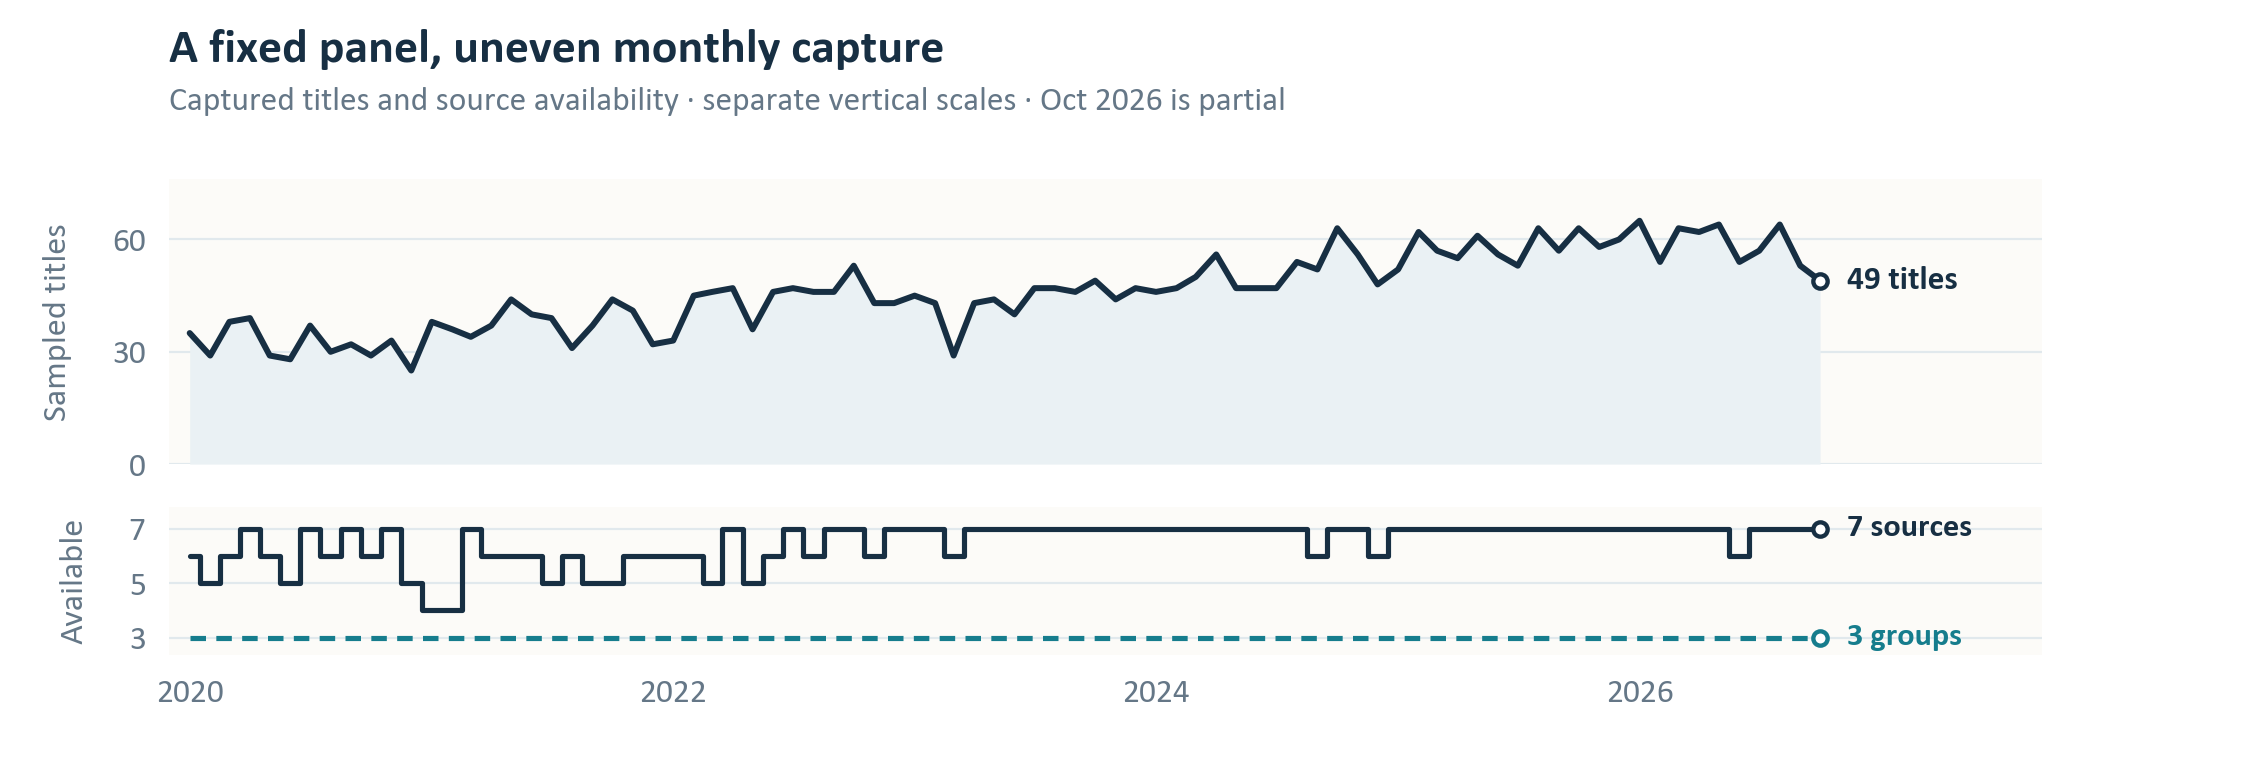

In [13]:
display(Image(filename=str(ROOT / 'outputs' / 'media_coverage.png')))

Upper panel: captured title counts. Lower panel: available outlets and source groups, on a separate vertical scale. Sparse or missing outlet-months reflect incomplete capture, not zero coverage of a topic.

The unit is a title. News headlines and HN user-submitted titles are analyzed in separate strata before aggregation; neither is a full-article argument or a record of what survey respondents read. Candidates are sampled by a deterministic hash with a fixed maximum per outlet-month. Items average within outlet, outlets within group, and groups across the monthly index. Both available-group and complete-group coverage are reported.

Exact normalized duplicates, repeated IDs, obvious promotions, out-of-period items and clearly foreign-only titles are audited. Unknown geographic relevance, near-duplicate syndication and suspected automated activity cannot be fully resolved from titles. HN is a selected technology community and may link to news; it is not a representative sample of US adults. Platform engagement, where returned, is a retrieval-vintage attention proxy and never a historical exposure weight.

RSS results are ranked and capped. The fixed panel improves comparability but is not a census or a politically representative sample. Retrospective search visibility, deletions and edited titles limit historical reconstruction. Content supply, engagement and actual exposure remain different quantities. Missingness and source composition are displayed so a change in the index can be assessed against a change in the sample.

## 6. Codebook, AI measurement and benchmarks

In [14]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[6][1][0]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Dimension,Operational proxy and boundary
0,Tone,"Pinned contextual P(positive) − P(negative), plus VADER. Negative ..."
1,Selection / salience,"Title shares for layoffs, hiring, prices, disinflation, growth, re..."
2,Framing,"Price level versus inflation rate, household versus aggregate, and..."
3,Factual calibration,"Screen explicit numerical claims; verify definition, period, units..."
4,Political attribution,Actor mentions and directional credit/blame proxies separately. Cr...


The codebook is frozen before project scoring, with subsequent relevance-screen amendments disclosed separately. The primary classifier is an immutably pinned CardiffNLP Twitter RoBERTa sentiment model. Model artifacts and inputs are hashed; the model is not fine-tuned on Michigan outcomes. VADER is the conventional dictionary comparison. Rule-based frame and salience indicators remain unvalidated literal proxies. Exact specifications and annotation instructions are retained in the reproducibility package.

The contextual model was introduced in 2022 with training text through 2021. Applying it to earlier titles uses a later language representation, so the full media analysis is retrospective pseudo-out-of-sample measurement. A genuinely historical deployment claim would require models, feeds and original wording frozen at each date. The dictionary and post-2022 sensitivities narrow, but do not eliminate, those limitations.

Benchmarks must match the proposed bias. The supplemental comparison on page 11 matches providers on identical official releases and estimates relative negative framing. This controls the release being covered but cannot equate all truthful components emphasized in a headline. An equivalent-surprise selection test remains prospective because archived expectations and a complete publication denominator are unavailable. Eight purposively selected unemployment-title percentages align with official releases; missing definitions/periods and intraday uncertainty prevent a full factual-accuracy classification.

Political-name swaps and source-label prefixes stress-test otherwise similar inputs. A changed actor can also change meaning. Evidence excerpts and versioned instructions accompany the annotation workflow. No title-only classifier establishes a reader’s availability, confirmation or negativity bias. Price-level wording and cumulative inflation do not establish anchoring to past prices without individual reference-price, belief or experimental evidence.

In [15]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[6][1][5]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Dimension,Jan–Sep 2026: balanced monthly mean
0,Tone,Score -0.199; 30.2% negative; 6.5% emotional-keyword proxy
1,Selection / salience,22.7% housing; 5.7% wages; 1.9% layoffs; 1.6% hiring
2,Framing,24.1% price level versus 18.2% inflation rate; 7.4% household vers...
3,Political attribution,15.5% actor mentions; 0.4% credit and 1.0% blame co-occurrence


Descriptive results cover 9 complete months and 536 titles. Titles average within outlets and outlets within source groups; the three groups and each month then receive equal weights. Topic and frame flags can overlap. These weighted content proxies are not pooled-title shares, respondent beliefs or an objective bias rate.

Political-name swaps changed 5/100 labels (mean absolute tone change 0.076); adding a Gothamist prefix changed 12/100 labels (mean absolute tone change 0.102), and a Reuters prefix 12/100 labels (mean absolute tone change 0.083). These stress tests motivate source-blind inputs; they do not establish political discrimination or factual bias.

## 7. Validation status and honest performance claims

The assignment explicitly requires at least 300 items labeled by two independent human annotators. No completed independent human labels were available. The project therefore prepares the blinded human worksheets, guide, adjudication procedure and validation code, and conducts independent AI reviews where available. AI reviews do not satisfy the human requirement. This is a material rubric limitation of the delivered project.

In [16]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[7][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Validation component,Status and interpretation
0,Stratified annotation packet,"At least 300 unique sampled items; separate blinded orders, eviden..."
1,Human agreement / kappa,Unavailable until two people independently complete labels; no fab...
2,Human accuracy / class F1,Unavailable without valid human reference/adjudication; model-dict...
3,Independent AI diagnostic,"Explicitly AI-labeled; useful for error discovery, not independent..."
4,Factual accuracy,Unverified corpus. Numerical-claim eligibility and a calibration w...
5,Adjudication,"Lock original files, identify disagreement, record a third judgmen..."


The validation code reports raw agreement, Cohen’s kappa, class precision/recall/F1, macro-F1 and source-specific performance only for completed and explicitly identified references. Uncertain and mixed labels must be handled transparently rather than silently mapped to convenient classes. An untouched future test set is needed after any classifier or rule change motivated by review.

A plausible AI tone score is insufficient validation of the economic construct. Titles can quote someone else, use sarcasm, attach blame to a target, describe good aggregate news with bad household implications, or express neutral factual adversity. These failure modes motivate short evidence excerpts, emotional-wording labels and frame-specific checks.

The two AI reviews agree on 92.0% of the original 300 titles (kappa 0.889). After relevance refinement, 277 remain eligible and 23 are excluded; the originals are preserved. On final-eligible three-class references, contextual concordance exceeds dictionary concordance in both reviews. Mixed/uncertain cases are excluded explicitly from three-class metrics. These are AI development diagnostics, not human accuracy. Class/source breakdowns are retained in the notebook.

## 8. Incremental prediction and statistical inference

M2 adds one prior-month tone measure; M3 adds cumulative prices and real income growth. All comparison models use the same February 2020 onward training pool, at least 36 prior months and identical tests. These refitted M1 predictions differ from the 2010 onward historical monitoring baseline. A controls-only model isolates M3’s media addition; lagged-sentiment and persistence models provide demanding benchmarks.

In [17]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[8][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Model,N,RMSE,MAE,95% coverage
0,Fitted AR1,44,4.32,3.57,100.0%
1,Autoregression + economics,44,4.66,3.91,95.5%
2,Autoregression + economics + media,44,4.62,3.93,97.7%
3,Economics + household controls,44,12.01,9.77,77.3%
4,M1: economics,44,11.85,10.01,79.5%
5,M2: economics + media,44,11.85,10.07,81.8%
6,M3: economics + media + controls,44,11.95,9.82,77.3%
7,Last observed sentiment,44,4.27,3.54,—


Common comparison dates: 2023-02-01 to 2026-09-01. On the common 44-month chronological assessment sample, adding the specified media variables reduces RMSE by 0.01 index points relative to M1. With lagged sentiment included, media reduces RMSE by 0.04 points.

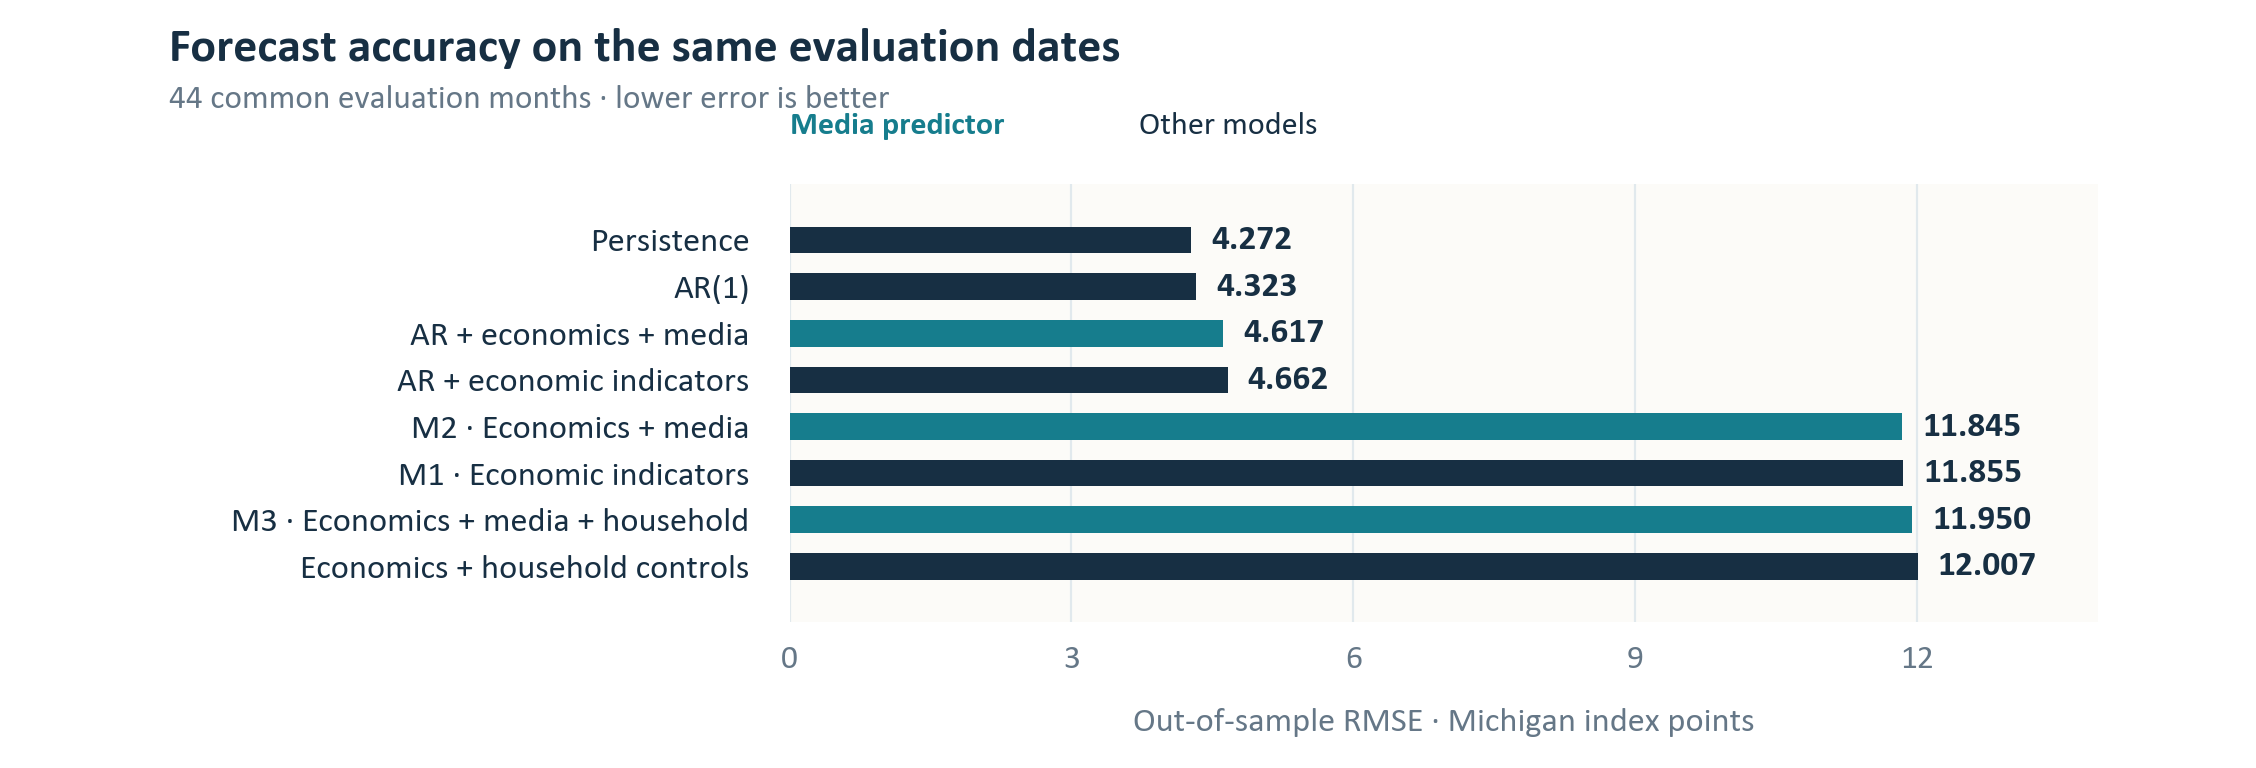

In [18]:
display(Image(filename=str(ROOT / 'outputs' / 'model_accuracy.png')))

Common-sample forecast errors. Lower error is useful only with stable performance, valid timing and measured inputs; it does not identify the mechanism.

Across 44 recursive M2 fits, the lagged-tone coefficient ranges from -1.57 to 17.54 and is positive in 37 fits. The three loss comparisons have BH q values of 0.949–0.949; none establishes a reliable gain. Dictionary, lag, source, framing and post-2022 checks are exploratory sensitivities. HAC standard errors cannot repair M1’s serial misspecification or structural breaks.

## 9. Causal reasoning and falsification

The selected assignment-permitted route is observational analysis plus a detailed causal-design proposal. A common economic shock can worsen sentiment and increase negative coverage; pessimistic audiences can seek negative content; publishers can respond to audience demand. Political affiliation can influence media choice and survey responses. Aggregate monthly regressions cannot separate these pathways without exposure or assignment information.

The proposed stronger design randomizes consenting participants to equally accurate summaries of the same official release, varying price-level versus inflation-rate and household versus aggregate emphasis. Keep numerical values, source credibility, length and reading difficulty constant. Measure baseline and post-treatment beliefs, perceived household conditions, recall and sentiment-related responses. Pre-register outcomes, contrasts, exclusion rules and a power calculation based on pilot variability. Obtain required institutional approval before recruitment; no participants were recruited for this project.

Random assignment would identify the effect of assigned framing on outcomes in that sample, subject to compliance, attrition and interference assumptions. A manipulation check verifies that framing changed without factual misunderstanding. Report intention-to-treat estimates, confidence intervals, attrition by arm and multiple-outcome adjustment. A placebo unrelated frame, neutral fact comprehension test and delayed follow-up can test alternative interpretations.

In [19]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[9][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Finding that would challenge a media-bias account,Why it matters
0,No stable incremental forecast improvement,Narrative measurement may contain no information beyond economic c...
1,Gap shrinks with household controls or mode adjustment,Economic experience or measurement explains the apparent discrepancy.
2,Negative stories are factually calibrated to bad outcomes,Adverse facts do not establish distorted coverage.
3,Matched-release asymmetry vanishes after surprise controls,Different news content can reflect different events rather than se...
4,No framing effect or recall mechanism in a powered experiment,Weakens the proposed mechanism under the tested conditions.


Transporting a sample experiment to the national Michigan index would require representative or reweighted sampling, actual population exposure estimates, outcome comparability, heterogeneous-effect estimates and defensible transportability assumptions. The experiment alone would not identify an effect on the national index. The full plan and assumptions are in docs/causal_design.md.

## 10. Provider comparison and monitoring

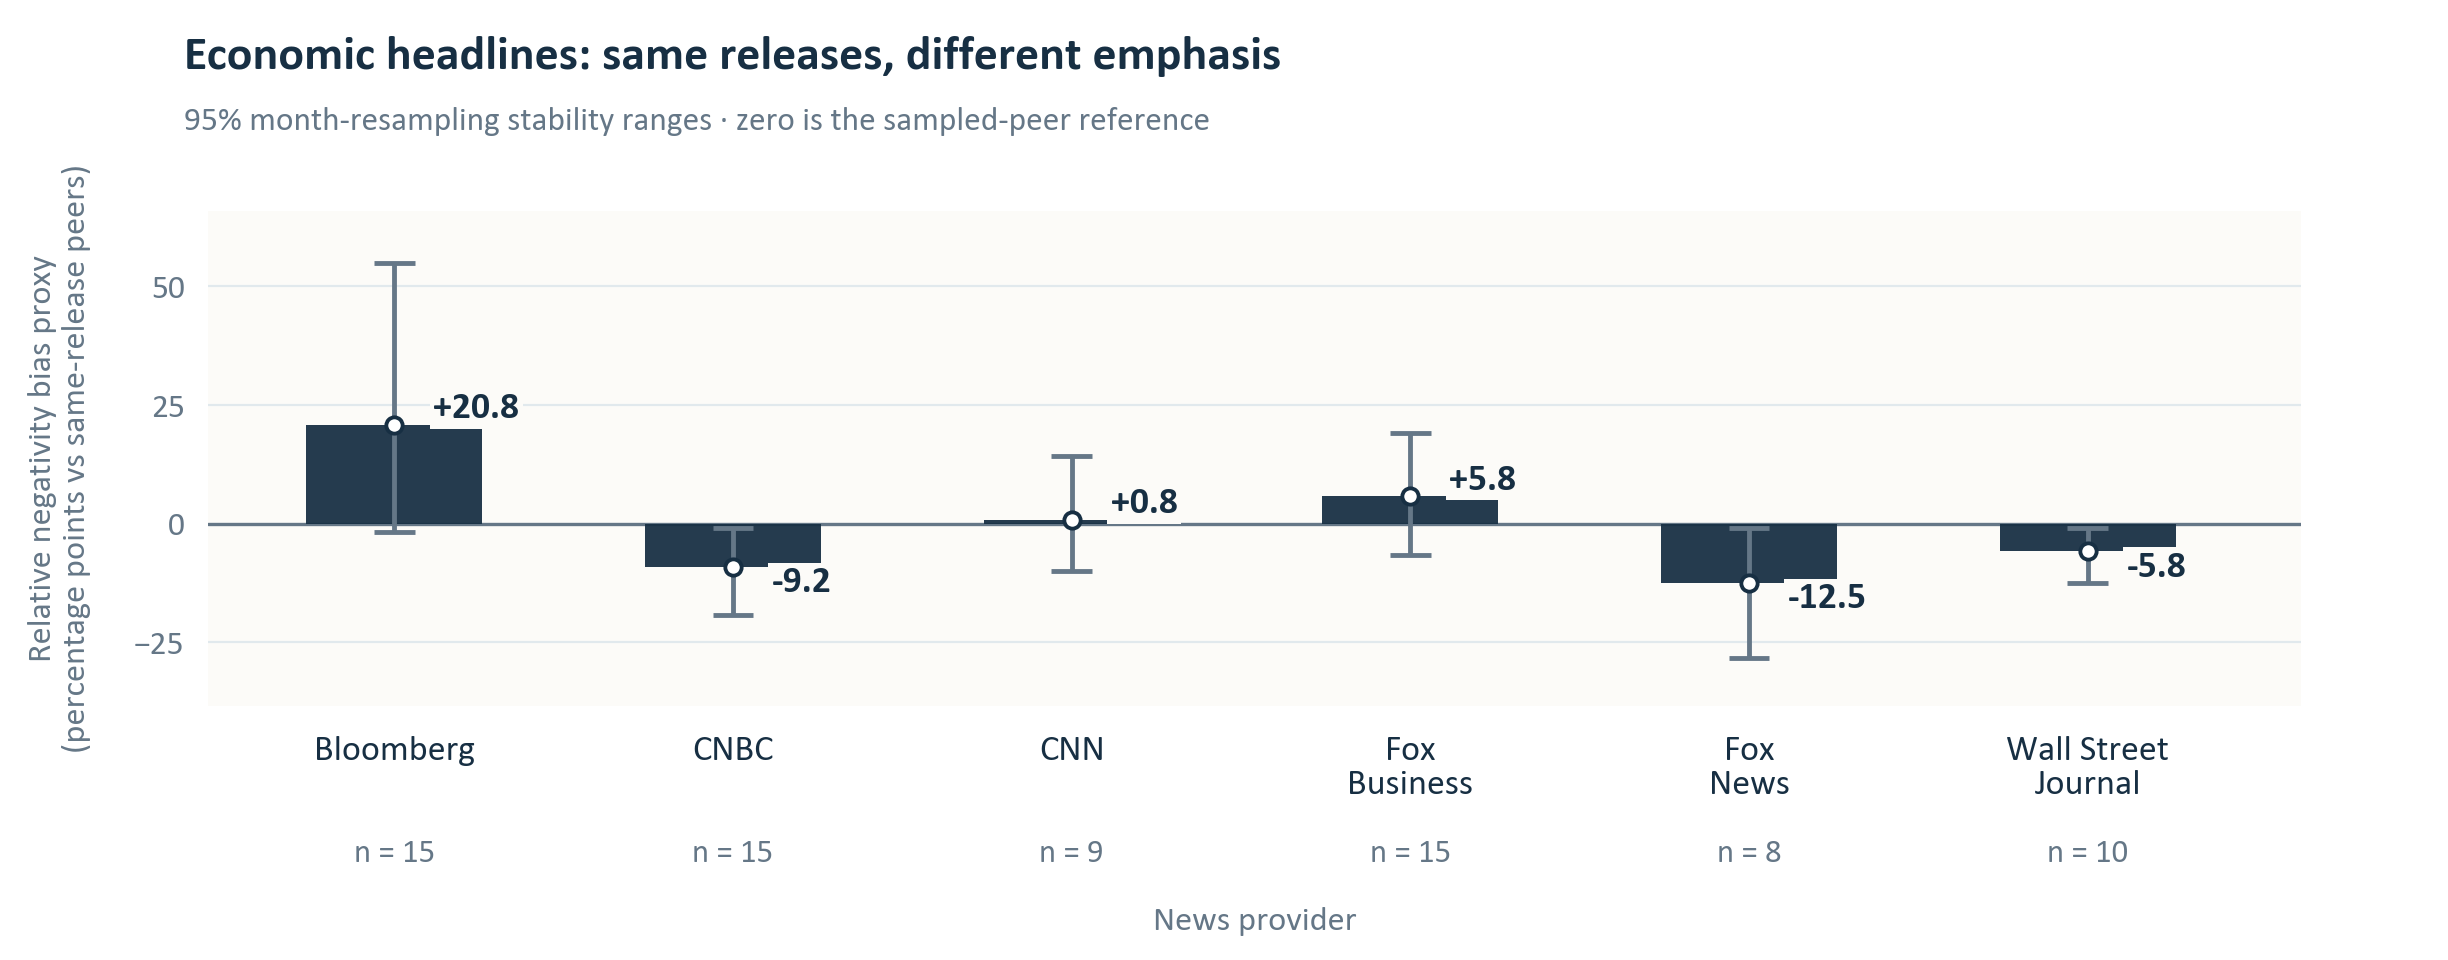

In [20]:
display(Image(filename=str(ROOT / 'outputs' / 'provider_bias.png')))

Separate matched-release supplement: 6 providers, 6 identical releases and 72 headlines. The shared set contains 5 employment and 1 CPI releases. Bars are each provider’s negative-headline share minus its equal-weight same-release peers, averaged across releases. Positive means relatively more negative wording; zero is a peer reference. n labels count headlines. The 95% stability ranges resample 6 calendar-month clusters and omit classification/retrieval uncertainty.

The supplement was retrieved October 15, 2026, after the October 13 economic cutoff. A coverage-only feasibility amendment selected six providers with six shared releases after the initial mandatory core supported only four. The y-axis measures relative negative framing; the x-axis identifies providers. Identical search rules, source-blind classification and equal event weights apply. CNBC, Fox News and Fox Business remain separate publications. The original monthly forecast corpus and results are unchanged.

A positive bar is not proof of distortion. Providers can truthfully emphasize different components, such as unemployment versus wages. Zero is not objective neutrality. Some signs change under dictionary or single-title sensitivities; the ranking is unstable. The new providers lack human validation, and the original AI review contains no CNBC or Fox items. Feed selection, few clusters and classification error limit interpretation. The chart does not measure ideological slant, factual dishonesty, exposure or a causal sentiment effect.

The interactive dashboard also displays sentiment, the economic prediction and intervals, the gap, media dimensions, source composition and performance. Preserve the October 13 economic snapshot when updating; October 23 Michigan final and October 29 GDP/PCE releases remain prospective. Election proximity is context, not an identified treatment.

Use provider differences to target matched-story review and forecast-risk scenarios. The separate investment backtest on page 12 compares macro/trend allocation with simple SPY/BIL portfolios; provider bars never select securities or trades.

## 11. Answers and investment conclusion

In [21]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[11][1][0]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Required research question,Answer supported by this project
0,How measure coverage bias?,"Define an event/accuracy benchmark; measure tone, selection, frami..."
1,Impact on Michigan sentiment?,Estimate lagged predictive associations with uncertainty; causal d...
2,How much do three macro indicators explain?,"Chronological M1 predictions, errors and intervals quantify model-..."
3,Which perceptual mechanisms measurable?,Price-level and household framing are content proxies; individual ...
4,Does media improve predictions?,Use the common-sample M1/M2/M3 and autoregressive comparisons on p...
5,What would contradict media bias?,"Successful household controls, unstable or null incremental predic..."


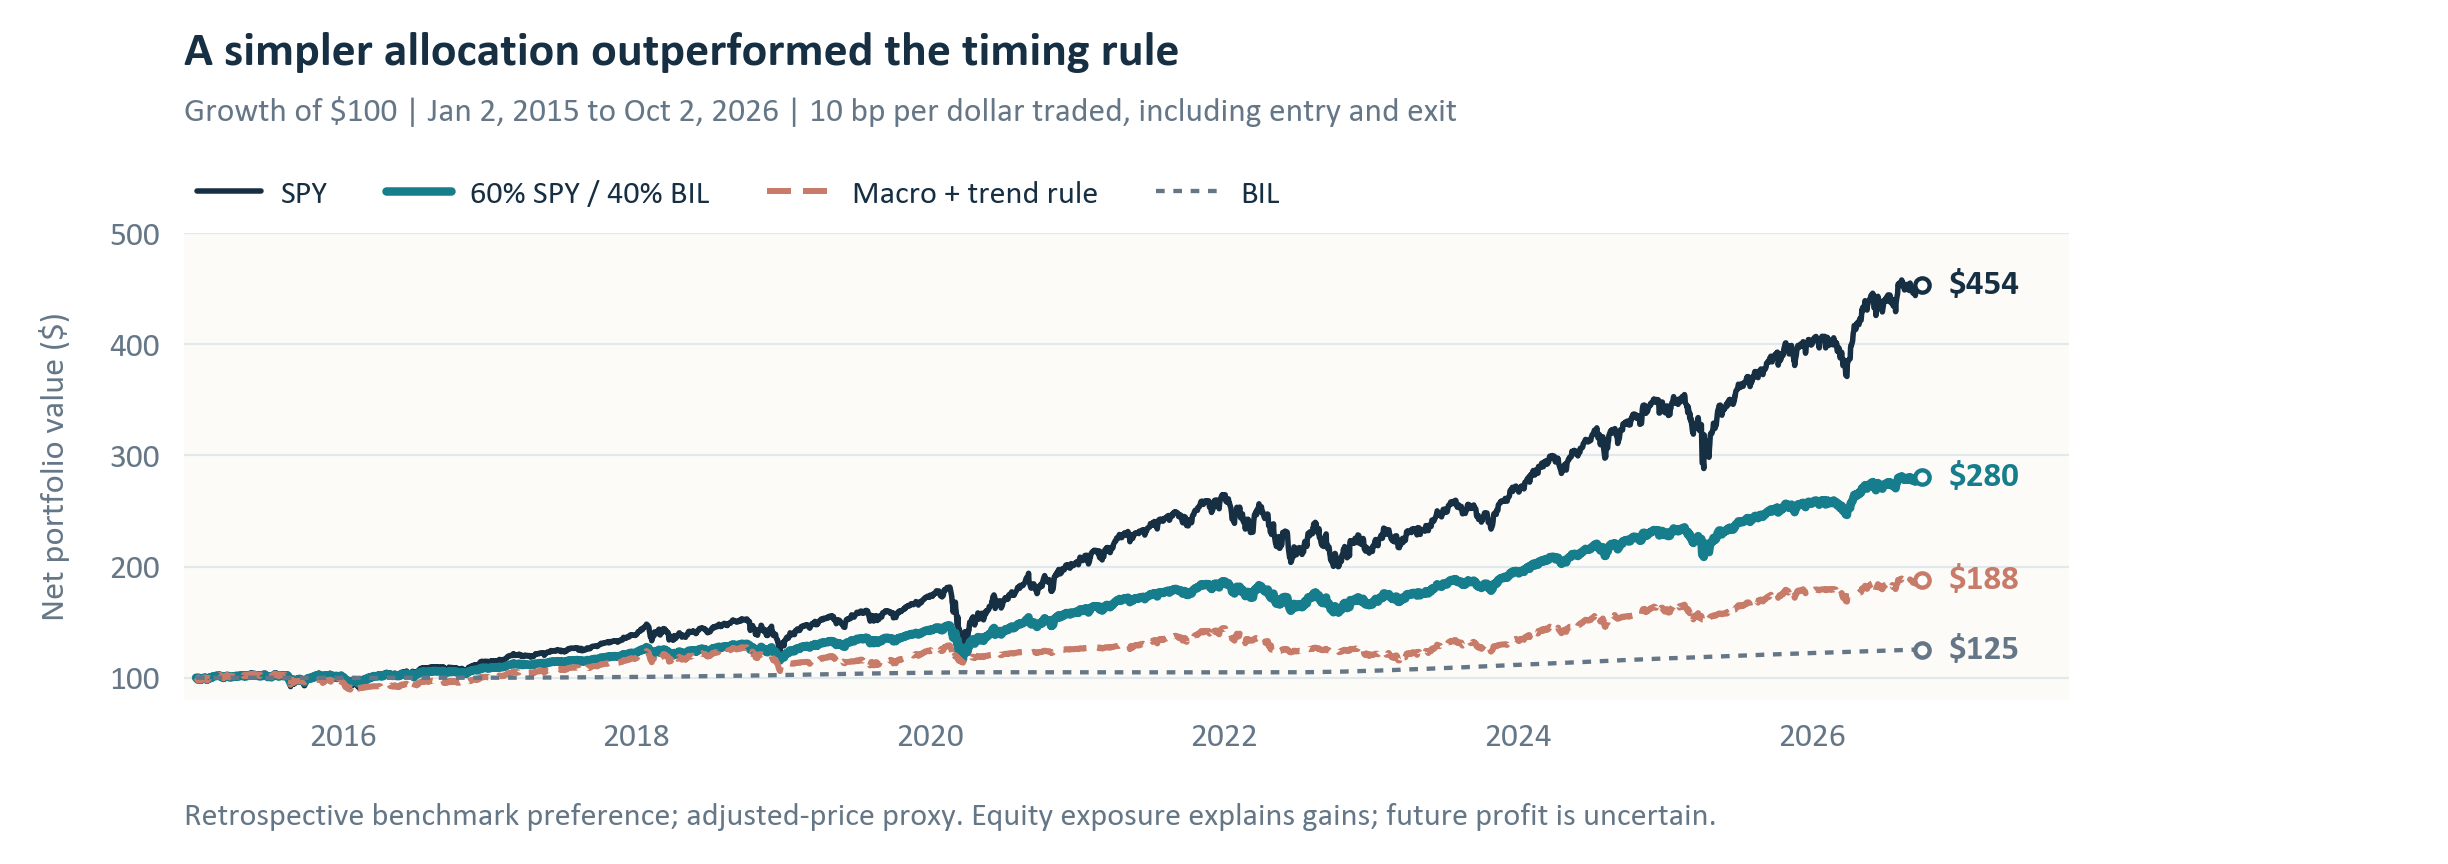

In [22]:
display(Image(filename=str(ROOT / 'outputs' / 'investment_strategy.png')))

October 17 retrospective extension: January 2, 2015–October 2, 2026 returns. Yahoo adjusted prices approximate reinvested distributions. Costs: 10 bps per dollar bought or sold in either ETF, including entry and final liquidation. No return-based threshold search.

In [23]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[11][1][2]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Portfolio: same dates and costs,Net CAGR,Worst drawdown
0,Monthly 60% SPY / 40% BIL,9.17%,-20.78%
1,Macro + trend allocation,5.52%,-20.11%
2,SPY buy-and-hold,13.74%,-33.72%
3,BIL buy-and-hold,1.94%,-0.23%


The historical comparison favors monthly 60% SPY / 40% BIL. The custom trend/Sahm-style rule holds 80% SPY when prior-month price exceeds its ten-month mean and the as-of three-month unemployment mean is less than 0.50 points above its trailing twelve-month low; otherwise 20%, with BIL the remainder. Incomplete labor windows are defensive. Both rules rebalance at the first joint-session close strictly after each monthly origin. Timing added little drawdown protection over 60/40.

Limits: no two-human media validation, corpus-wide factual audit or respondent exposure. Backtests use retrospective adjusted prices and assumed costs, omit taxes and nonlinear impact, and lack untouched validation. Gap/media tilts use revised or reconstructed inputs; all 44 gap signals add equity exposure. Historical net profit establishes neither alpha nor future profit. Details: docs/INVESTMENT_PROTOCOL.md.

Primary sources: [Michigan index](https://www.sca.isr.umich.edu/), [calendar](https://data.sca.isr.umich.edu/fetchdoc.php?docid=79628), [web transition](https://www.sca.isr.umich.edu/files/methodtransitionannouncement2024.pdf), [2026 methodology](https://www.sca.isr.umich.edu/files/partisaneconomy202607_revised.pdf); [BLS CPS](https://www.bls.gov/cps/) and [shutdown](https://www.bls.gov/cps/methods/2025-federal-government-shutdown-impact-cps.htm); [BEA PCE](https://www.bea.gov/news/2026/personal-income-and-outlays-august-2026), [GDP](https://www.bea.gov/data/gdp/gross-domestic-product); [ALFRED](https://alfred.stlouisfed.org/); [CardiffNLP](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest); [VADER](https://github.com/cjhutto/vaderSentiment); [HN](https://hn.algolia.com/api); [SPY](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-sp-500-etf-trust-spy) and [BIL](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-bloomberg-1-3-month-t-bill-etf-bil). [Budak et al. (2016)](https://5harad.com/papers/mediabias.pdf) and [Gentzkow–Shapiro (2010)](https://web.stanford.edu/~gentzkow/research/biasmeas.pdf) define distinct framing/slant constructs, without validating this proxy. Sources, code, provenance, codebook, notebook and AI_USE.md accompany the project; no participants, trades or institutional submission.

## Reproducibility and limitations

See `README.md`, `SNAPSHOT.md`, `AI_USE.md`, the source manifest, codebook, causal proposal, and annotation-validation protocol. A fresh download can change mutable feed results. Saved aggregate outputs preserve this snapshot, while item-level data remain local.